# Modules 5 & 6: ML Equity Strategy and Portfolio Optimisation

**Business question (Module 5):** Can ML identify stocks with superior future returns?
**Business question (Module 6):** Does turning ML predictions into a portfolio beat equal-weight and traditional Markowitz portfolios after costs?

**Chain:** price and macro data → predicted next-month return → monthly stock ranking → portfolio weights → backtest (return, risk, drawdown, VaR) → investment decision.

**What you will learn:** look-ahead bias, walk-forward validation, the information coefficient (IC), Markowitz optimisation, backtesting with transaction costs, and Value-at-Risk.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_market_data.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
RF_ANNUAL = 0.065          # risk-free rate for Sharpe (assumed, Indian T-bill level)
COST = 0.001               # 10 bps transaction cost per unit of turnover
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect

In [2]:
df = pd.read_csv(DATA / "nova_market_data.csv", parse_dates=["Date"]).sort_values(["Ticker", "Date"]).reset_index(drop=True)
print(df.shape, "| tickers:", df.Ticker.nunique(), "| dates:", df.Date.nunique(), "|", df.Date.min().date(), "to", df.Date.max().date())
print("Is `Return` today's close-to-close return?",
      np.allclose(df.groupby("Ticker").Close.pct_change().fillna(df.Return), df.Return))
df.head()

(21855, 15) | tickers: 15 | dates: 1457 | 2021-01-29 to 2026-08-31
Is `Return` today's close-to-close return? True


,Ticker,Date,Open,High,Low,Close,Volume,Sector,Market_Return,GDP_Growth,Interest_Rate,VIX,Return,Momentum_20D,Volatility_20D
0,AXISBANK,2021-01-29,1504.139825,1569.087319,1520.801279,1537.821733,1132073,Banking,0.003240,5.306784,7.138969,15.441092,0.022446,-0.003727,0.016400
1,AXISBANK,2021-02-01,1535.570827,1566.317153,1531.170028,1552.422487,1525060,Banking,-0.015363,6.742571,6.427051,17.421802,0.009494,0.013173,0.016439
2,AXISBANK,2021-02-02,1565.277641,1531.531661,1507.435188,1513.267607,2003396,Banking,-0.005076,6.191520,5.948312,18.962496,-0.025222,-0.024618,0.017170
3,AXISBANK,2021-02-03,1514.383611,1507.544183,1466.978060,1493.300906,1037253,Banking,-0.006728,6.724423,8.563131,25.346364,-0.013194,-0.022286,0.017073
4,AXISBANK,2021-02-04,1489.172351,1516.484362,1482.721967,1513.172289,505705,Banking,0.004209,6.466376,5.884838,15.202102,0.013307,-0.017676,0.017245


**Look-ahead check:** `Return` is *today's* return, and Momentum_20D / Volatility_20D include today's close. They are fine as features for predicting **future** returns, but must never be the target.

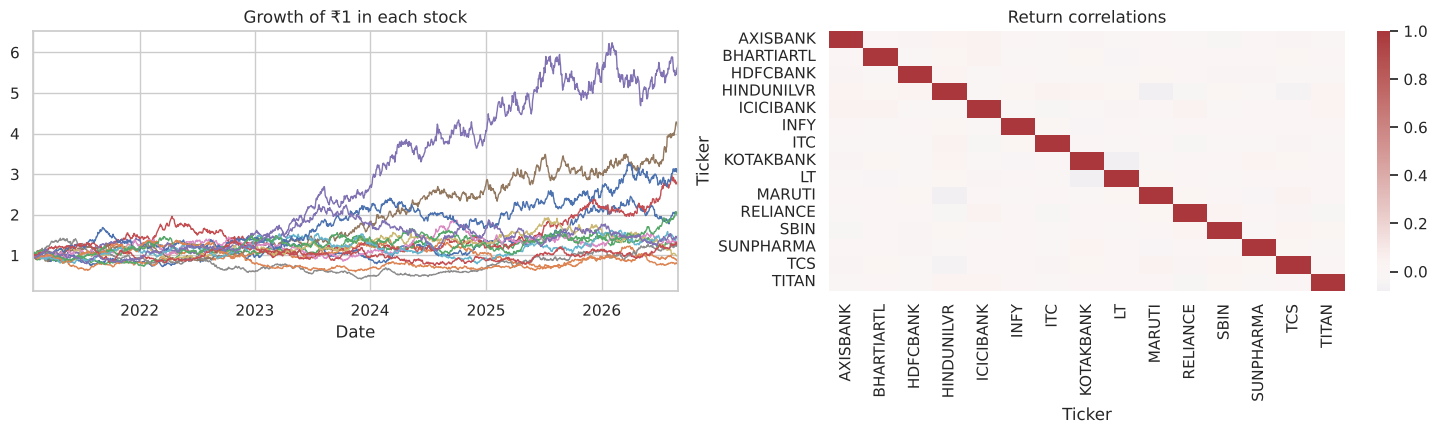

Ticker,SBIN,BHARTIARTL,LT,TCS,HDFCBANK,KOTAKBANK,ITC,TITAN,MARUTI,AXISBANK,SUNPHARMA,HINDUNILVR,RELIANCE,INFY,ICICIBANK
annual mean return,-0.004,0.014,0.035,0.078,0.084,0.084,0.09,0.099,0.109,0.162,0.166,0.218,0.239,0.288,0.34


In [3]:
rets = df.pivot(index="Date", columns="Ticker", values="Return")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
(1 + rets).cumprod().plot(ax=ax[0], legend=False, title="Growth of ₹1 in each stock", lw=1)
sns.heatmap(rets.corr(), cmap="vlag", center=0, ax=ax[1]).set_title("Return correlations")
plt.tight_layout(); plt.show()
(rets.mean() * 252).sort_values().round(3).to_frame("annual mean return").T

## 2. Module 5: features and target (month-end snapshots)
We rebalance **monthly**, so we build one row per stock per month-end:
- **Target:** forward 21-trading-day return, `Close(t+21) / Close(t) − 1`.
- **Features (known at t):** 20-day momentum and volatility, 60- and 120-day momentum, 5-day return, volume vs its 20-day average, 20-day market return, VIX, interest rate, GDP growth, sector.

In [4]:
g = df.groupby("Ticker")
df["Target"] = g.Close.shift(-21) / df.Close - 1
df["Mom_60"] = g.Close.pct_change(60)
df["Mom_120"] = g.Close.pct_change(120)
df["Ret_5"] = g.Close.pct_change(5)
df["Vol_Ratio"] = df.Volume / g.Volume.transform(lambda s: s.rolling(20).mean())
df["Mkt_20"] = g.Market_Return.transform(lambda s: (1 + s).rolling(20).apply(np.prod, raw=True) - 1)
df["Month"] = df.Date.dt.to_period("M")
month_end = df.groupby(["Ticker", "Month"]).Date.transform("max") == df.Date
snap = df[month_end].dropna(subset=["Mom_120", "Vol_Ratio"]).copy()
FEATS = ["Momentum_20D", "Volatility_20D", "Mom_60", "Mom_120", "Ret_5", "Vol_Ratio", "Mkt_20", "VIX", "Interest_Rate", "GDP_Growth"]
snap = pd.concat([snap, pd.get_dummies(snap.Sector, prefix="Sec", dtype=float)], axis=1)
FEATS += [c for c in snap.columns if c.startswith("Sec_")]
dates = np.sort(snap.Date.unique())
print("Month-end snapshots:", len(snap), "| rebalance dates:", len(dates))

Month-end snapshots: 930 | rebalance dates: 62


## 3. Walk-forward validation
Never shuffle time-series data. At each month-end from Jan 2023 we:
1. train on all snapshots whose 21-day target was **already known** (dated at least one month earlier),
2. predict next-month returns for the 15 stocks,
3. move forward one month and repeat.

Models: historical-mean baseline, ridge regression, random forest, LightGBM.

In [5]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMRegressor
from scipy.stats import spearmanr

models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random forest": RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=200, max_depth=3, learning_rate=0.03, min_child_samples=30, subsample=0.8, subsample_freq=1, random_state=SEED, verbose=-1),
}
test_dates = [d for d in dates if d >= np.datetime64("2023-01-01") and not np.isnan(snap.loc[snap.Date == d, "Target"]).all()]
preds = []
for d in test_dates:
    train = snap[(snap.Date < d - np.timedelta64(31, "D")) & snap.Target.notna()]
    test = snap[snap.Date == d]
    out = test[["Date", "Ticker", "Target"]].copy()
    out["Hist_mean"] = test.Ticker.map(train.groupby("Ticker").Target.mean())
    for name, m in models.items():
        out[name] = m.fit(train[FEATS], train.Target).predict(test[FEATS])
    preds.append(out)
preds = pd.concat(preds).dropna(subset=["Target"])
print("Out-of-sample months:", preds.Date.nunique())

Out-of-sample months: 43


**Information coefficient (IC):** on each date, the rank correlation between predicted and actual returns across the 15 stocks. For stock selection the *ranking* matters more than the exact return. An average IC of 0.03–0.05 is considered useful in practice. The t-stat tells us whether the average IC is distinguishable from zero.

In [6]:
MODELS = ["Hist_mean"] + list(models)
ic = preds.groupby("Date").apply(lambda x: pd.Series({m: spearmanr(x[m], x.Target)[0] for m in MODELS}))
rmse = {m: np.sqrt(((preds[m] - preds.Target) ** 2).mean()) for m in MODELS}
evals = pd.DataFrame({"mean IC": ic.mean(), "IC t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)), "share of months IC>0": (ic > 0).mean(), "RMSE": pd.Series(rmse)}).round(4)
evals

,mean IC,IC t-stat,share of months IC>0,RMSE
Hist_mean,0.0051,0.1468,0.4651,0.0852
Ridge,-0.0400,-1.0450,0.3953,0.0856
Random forest,-0.0086,-0.2039,0.5349,0.0851
LightGBM,-0.0189,-0.4466,0.5116,0.0866


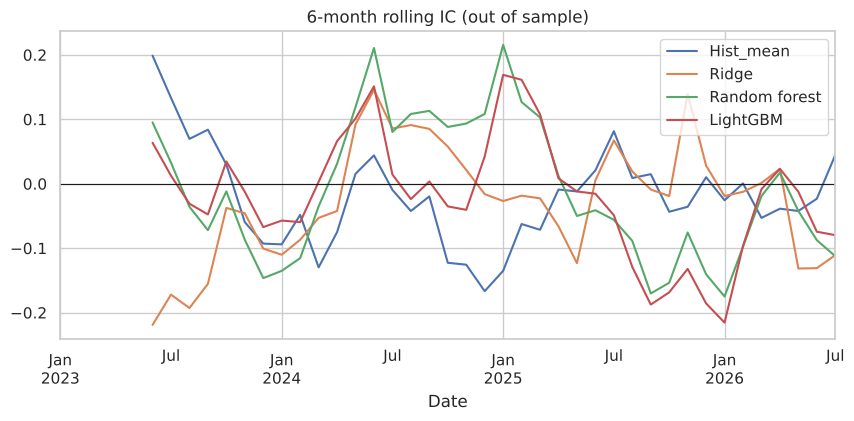

In [7]:
ic.rolling(6).mean().plot(figsize=(10, 4), title="6-month rolling IC (out of sample)"); plt.axhline(0, c="k", lw=0.8); plt.show()

## 4. Module 5: stock ranking and the ML portfolio
At each rebalance date: predict → rank → pick the **top 5** → hold them equally weighted for the month. We use the model with the best mean IC.

In [8]:
best_model = evals["mean IC"].drop("Hist_mean").idxmax()
print("Model used for ranking:", best_model)
preds["Rank"] = preds.groupby("Date")[best_model].rank(ascending=False)
preds[preds.Date == preds.Date.max()].sort_values("Rank")[["Ticker", best_model, "Rank", "Target"]].round(4)

Model used for ranking: Random forest


,Ticker,Random forest,Rank,Target
17462,SBIN,0.0309,1.0,-0.0317
7263,ICICIBANK,0.0219,2.0,0.0198
13091,LT,0.0191,3.0,-0.1429
1435,AXISBANK,0.0189,4.0,0.0940
11634,KOTAKBANK,0.0185,5.0,0.0748
14548,MARUTI,0.0176,6.0,0.0087
2892,BHARTIARTL,0.0148,7.0,-0.1331
10177,ITC,0.0135,8.0,-0.0521
4349,HDFCBANK,0.0119,9.0,-0.0218
21833,TITAN,0.0107,10.0,-0.0682


## 5. Module 6: three portfolio strategies
1. **Equal weight:** 1/15 in every stock.
2. **Markowitz (max Sharpe):** expected returns and covariance from the past 252 days; long-only; at most 30% per stock. Covariance uses Ledoit-Wolf shrinkage, which makes it more stable.
3. **ML top-5:** equal weight in the 5 highest-ranked stocks.
4. **ML + Markowitz:** the optimiser fed with ML-predicted returns instead of historical means.

All rebalance monthly and pay 10 bps per unit of turnover.

In [9]:
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
tickers = rets.columns
def max_sharpe(mu, cov, cap=0.30):
    n = len(mu); rf = RF_ANNUAL / 252
    f = lambda w: -(w @ mu - rf) / np.sqrt(w @ cov @ w)
    res = minimize(f, np.ones(n) / n, bounds=[(0, cap)] * n, constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
    return res.x if res.success else np.ones(n) / n

weights = {k: {} for k in ["Equal weight", "Markowitz", "ML top-5", "ML + Markowitz"]}
for d in sorted(preds.Date.unique()):
    hist = rets.loc[:d].iloc[-252:]
    cov = LedoitWolf().fit(hist.values).covariance_
    p = preds[preds.Date == d].set_index("Ticker").reindex(tickers)
    weights["Equal weight"][d] = pd.Series(1 / len(tickers), tickers)
    weights["Markowitz"][d] = pd.Series(max_sharpe(hist.mean().values, cov), tickers)
    top5 = p[best_model].nlargest(5).index
    weights["ML top-5"][d] = pd.Series(np.where(tickers.isin(top5), 0.2, 0.0), tickers)
    weights["ML + Markowitz"][d] = pd.Series(max_sharpe(p[best_model].values / 21, cov), tickers)

def backtest(wdict):
    w = pd.DataFrame(wdict).T.sort_index()
    daily_w = w.reindex(rets.index).ffill().shift(1)          # weights set at close t apply from t+1
    daily_w = daily_w.loc[w.index[0]:].dropna(how="all")
    gross = (daily_w * rets.loc[daily_w.index]).sum(axis=1)
    turnover = w.diff().abs().sum(axis=1).fillna(1.0)          # first rebalance buys everything
    cost = (turnover * COST).reindex(gross.index).shift(1).fillna(0)
    return gross - cost, turnover

results = {k: backtest(v) for k, v in weights.items()}
daily = pd.DataFrame({k: v[0] for k, v in results.items()})
daily.index.min().date(), daily.index.max().date()

(datetime.date(2023, 2, 1), datetime.date(2026, 8, 31))

## 6. Backtest performance metrics

In [10]:
def metrics(r, turnover):
    eq = (1 + r).cumprod(); yrs = len(r) / 252
    cagr = eq.iloc[-1] ** (1 / yrs) - 1; vol = r.std() * np.sqrt(252)
    dd = (eq / eq.cummax() - 1).min()
    return pd.Series({"CAGR": cagr, "Volatility": vol, "Sharpe": (r.mean() * 252 - RF_ANNUAL) / vol,
                      "Max drawdown": dd, "Calmar": cagr / abs(dd), "Avg monthly turnover": turnover.iloc[1:].mean()})
perf = pd.DataFrame({k: metrics(daily[k], results[k][1]) for k in daily}).T.round(3)
perf

,CAGR,Volatility,Sharpe,Max drawdown,Calmar,Avg monthly turnover
Equal weight,0.150,0.076,1.019,-0.045,3.360,0.000
Markowitz,0.141,0.120,0.619,-0.137,1.033,0.374
ML top-5,0.066,0.128,0.054,-0.158,0.417,1.343
ML + Markowitz,0.099,0.117,0.312,-0.139,0.716,1.253


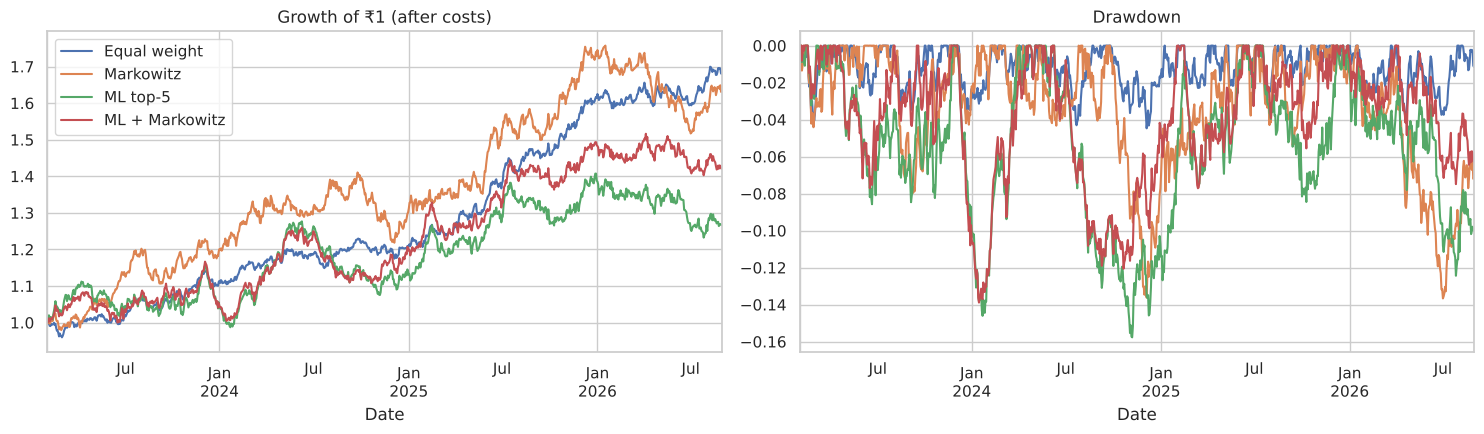

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
(1 + daily).cumprod().plot(ax=ax[0], title="Growth of ₹1 (after costs)")
((1 + daily).cumprod() / (1 + daily).cumprod().cummax() - 1).plot(ax=ax[1], title="Drawdown", legend=False)
plt.tight_layout(); plt.show()

**Is the difference real?** A 2–3 year backtest is short. We bootstrap monthly excess returns of the ML portfolio over equal weight to see how often the gap could be just luck.

In [12]:
monthly = (1 + daily).resample("ME").prod() - 1
excess = monthly["ML top-5"] - monthly["Equal weight"]
rng = np.random.default_rng(SEED)
boot = np.array([rng.choice(excess.values, len(excess)).mean() for _ in range(5000)])
print(f"Mean monthly excess return ML top-5 vs equal weight: {excess.mean():.4f}")
print(f"Bootstrap 90% interval: [{np.percentile(boot, 5):.4f}, {np.percentile(boot, 95):.4f}]  | P(excess > 0) = {(boot > 0).mean():.2f}")

Mean monthly excess return ML top-5 vs equal weight: -0.0062
Bootstrap 90% interval: [-0.0144, 0.0019]  | P(excess > 0) = 0.10


## 7. Value-at-Risk for the recommended portfolio
VaR answers: "on a bad day (1 in 100), how much could we lose?" We compute the **1-day 99% VaR** three ways and **expected shortfall** (the average loss on days worse than VaR). Then we backtest it: with a rolling 250-day historical VaR, losses should exceed VaR on about 1% of days.

In [13]:
from scipy.stats import norm
choice = perf["Sharpe"].idxmax()
r = daily[choice]
var_hist = -np.percentile(r, 1)
var_param = -(r.mean() + norm.ppf(0.01) * r.std())
sims = rng.multivariate_normal(rets.mean().values, rets.cov().values, 100_000) @ pd.DataFrame(weights[choice]).T.iloc[-1].values
var_mc = -np.percentile(sims, 1)
es = -r[r <= -var_hist].mean()
var_tbl = pd.Series({"Historical VaR 99%": var_hist, "Parametric VaR 99%": var_param, "Monte Carlo VaR 99%": var_mc, "Expected shortfall 99%": es}).round(4)
print("Portfolio:", choice); print(var_tbl)
print(f"On a ₹100 crore position, 1-day 99% historical VaR ≈ ₹{var_hist*100:.2f} crore")

Portfolio: Equal weight
Historical VaR 99%        0.0113
Parametric VaR 99%        0.0106
Monte Carlo VaR 99%       0.0106
Expected shortfall 99%    0.0120
dtype: float64
On a ₹100 crore position, 1-day 99% historical VaR ≈ ₹1.13 crore


In [14]:
roll_var = -r.rolling(250).quantile(0.01).shift(1)
exceed = (r < -roll_var).loc[roll_var.dropna().index]
print(f"VaR backtest: {exceed.sum()} exceptions in {len(exceed)} days = {exceed.mean():.2%} (expected 1%)")

VaR backtest: 8 exceptions in 684 days = 1.17% (expected 1%)


## 8. Save outputs

In [15]:
perf.to_csv(OUT / "m6_portfolio_performance.csv")
evals.to_csv(OUT / "m5_model_evaluation.csv")
var_tbl.to_csv(OUT / "m6_var.csv")
pd.DataFrame(weights[choice]).T.iloc[-1].round(4).to_csv(OUT / "m6_latest_weights.csv")
print("Saved; recommended strategy:", choice)

Saved; recommended strategy: Equal weight


## 9. Conclusions
Read the tables above when writing the report; the key messages are:
1. **Prediction:** monthly stock returns are close to unpredictable here. The IC of every model is small and its t-stat is far from significant. ML does not reliably identify superior stocks in this data.
2. **Portfolios:** equal weight wins clearly (Sharpe ≈ 1.0, max drawdown ≈ −4.5%), ahead of Markowitz (≈ 0.6) and the ML portfolios (≈ 0.05–0.3). ML strategies turn over more than 100% a month, so costs and concentration hurt them. Bootstrap: only a ~10% chance that ML top-5 truly beats equal weight.
3. **Recommendation:** run the equity book as a diversified, low-turnover core (equal weight or risk-based), keep the ML ranking as a research signal with a small tracking-error budget, and limit equity capital accordingly.
4. **Risk:** report the 1-day 99% VaR and expected shortfall; the VaR backtest checks the model is not understating risk.
5. **Note:** equal weight is modelled as constant weights (daily rebalanced), so its turnover shows as 0; in practice monthly drift-rebalancing costs are small.
6. **Limits:** 15 stocks, ~3.5 years out of sample, synthetic prices, no dividends or taxes.